# Lab 11 — PCA and Feature Reduction
### In-class demonstration | Wine classification

## 1. Dataset

The Wine dataset has 13 measurements for each sample. Start by looking at the feature names and ranges before deciding whether any information is repeated.

In [1]:
# Load the dataset as a DataFrame so feature names remain visible.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Keep the original feature names; we will need them when interpreting correlations.
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
# First number = samples; second number = original numerical features.
print('Shape:', X.shape)
print('Classes:', y.value_counts().sort_index().to_dict())
display(X.head())
# Compare ranges and standard deviations: the features use different scales.
print(X.describe().round(2))

Shape: (178, 13)
Classes: {0: 59, 1: 71, 2: 48}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


       alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  \
count   178.00      178.00  178.00             178.00     178.00   
mean     13.00        2.34    2.37              19.49      99.74   
std       0.81        1.12    0.27               3.34      14.28   
min      11.03        0.74    1.36              10.60      70.00   
25%      12.36        1.60    2.21              17.20      88.00   
50%      13.05        1.87    2.36              19.50      98.00   
75%      13.68        3.08    2.56              21.50     107.00   
max      14.83        5.80    3.23              30.00     162.00   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count         178.00      178.00                178.00           178.00   
mean            2.30        2.03                  0.36             1.59   
std             0.63        1.00                  0.12             0.57   
min             0.98        0.34                  0.13             0.41   
25%         

## 2. Which features vary together?

Covariance shows how variables change together, but it depends on their units. Correlation scales these relationships to the range −1 to +1, which makes comparisons across feature pairs easier.

Look for similar patterns on the correlation plot, not just the largest numbers on the covariance plot.

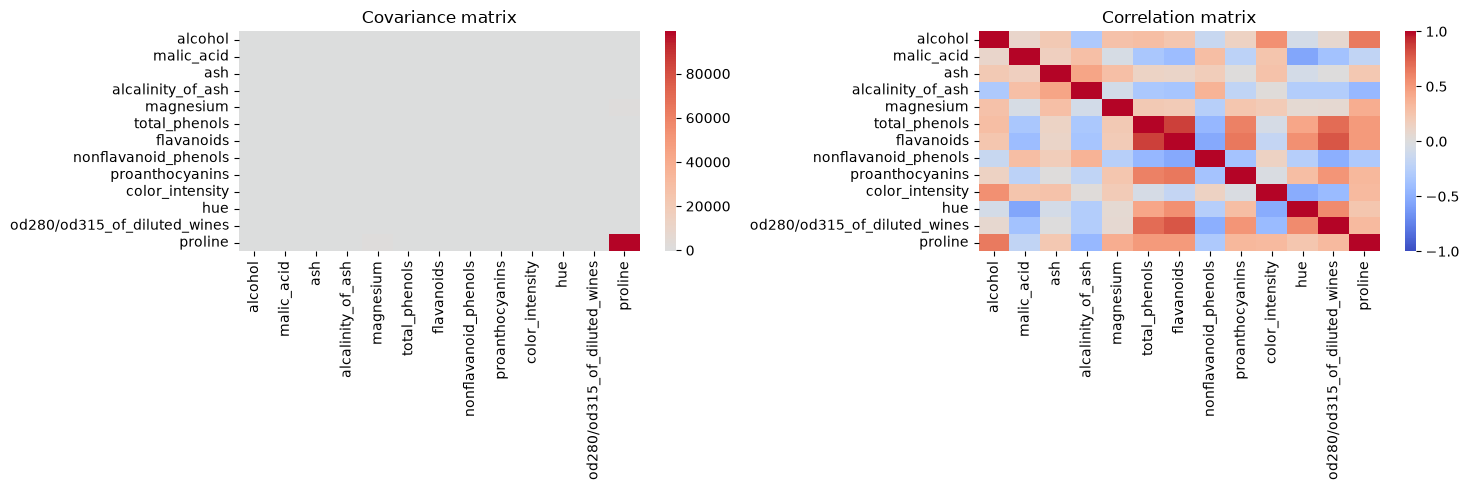

In [2]:
# Covariance depends on units; correlation makes pairs easier to compare.
# Correlation is scale-independent; covariance is not.
# Both plots describe feature relationships, but their numbers mean different things.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# Covariance magnitude changes with units; large values alone do not imply stronger relationships.
sns.heatmap(X.cov(), cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('Covariance matrix')
# Correlation ranges from -1 to +1; values near either end show strong linear relationships.
sns.heatmap(X.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Correlation matrix')
plt.tight_layout(); plt.show()

## 3. Find the strongest feature relationship

Find a pair with a large absolute correlation and inspect its scatter plot. A strong correlation suggests overlapping information, not necessarily that one feature is useless for prediction.

,,Absolute correlation
total_phenols,flavanoids,0.864564
flavanoids,od280/od315_of_diluted_wines,0.787194
total_phenols,od280/od315_of_diluted_wines,0.699949
flavanoids,proanthocyanins,0.652692
alcohol,proline,0.643720
total_phenols,proanthocyanins,0.612413
hue,od280/od315_of_diluted_wines,0.565468
malic_acid,hue,0.561296
alcohol,color_intensity,0.546364
flavanoids,hue,0.543479


Selected pair: total_phenols / flavanoids
Correlation: 0.865


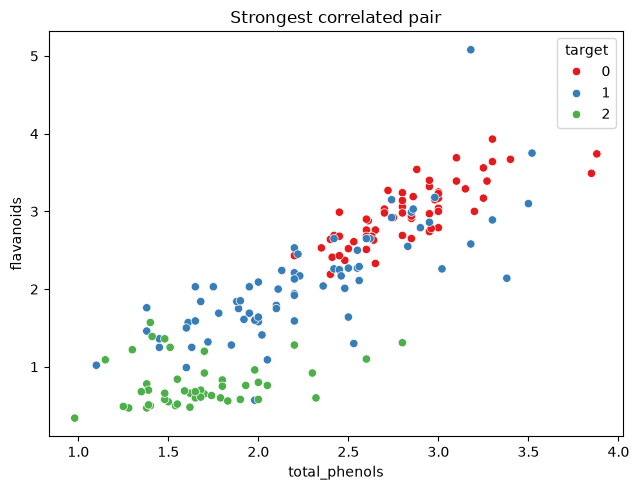

In [3]:
# Sort feature pairs by absolute correlation, excluding self-correlations.
# Calculate pairwise Pearson correlations between the 13 original measurements.
corr = X.corr()
# Use absolute values: strong negative and positive correlations can both indicate redundancy.
# Keep only the upper triangle so each feature pair appears once.
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
display(pairs.head(10).rename('Absolute correlation').to_frame())
# Pick the strongest pair to inspect, but do not assume one must be removed.
feature_a, feature_b = pairs.index[0]
print('Selected pair:', feature_a, '/', feature_b)
print('Correlation:', round(corr.loc[feature_a, feature_b], 3))
fig, ax = plt.subplots(figsize=(6.5, 5))
# A narrow sloping cloud indicates a strong linear relationship.
# Colours reveal whether the relationship is also useful for class separation.
sns.scatterplot(x=X[feature_a], y=X[feature_b], hue=y, palette='Set1', ax=ax)
ax.set_title('Strongest correlated pair'); plt.tight_layout(); plt.show()

## 4. Does keeping both features help?

Test the first feature, the second feature, and both together using the same cross-validation procedure. This checks whether the second measurement adds useful predictive information.

If two correlated measurements still improve accuracy together, correlation alone is not enough reason to discard one.

,CV accuracy
total_phenols,0.646
flavanoids,0.775
Both features,0.776


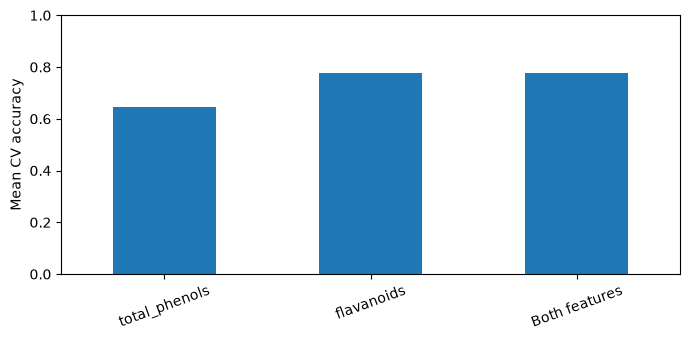

In [4]:
# Standardize inside each CV fold to avoid leakage.
# Use identical CV splits and identical models.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Cross-validation estimates performance on several held-out folds rather than one split.
def knn_cv(data):
    pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])
    return cross_val_score(pipe, data, y, cv=cv, scoring='accuracy').mean()
# Compare each feature alone with both together: correlation does not prove identical predictive value.
results_pair = pd.Series({feature_a: knn_cv(X[[feature_a]]),
                          feature_b: knn_cv(X[[feature_b]]),
                          'Both features': knn_cv(X[[feature_a, feature_b]])})
display(results_pair.rename('CV accuracy').to_frame().round(3))
results_pair.plot.bar(figsize=(7, 3.5), ylim=(0, 1), ylabel='Mean CV accuracy', rot=20)
plt.tight_layout(); plt.show()

## 5. Reduce features using correlation

Choose a correlation threshold and drop one feature from each highly correlated pair. Calculate the correlations on training data only, then apply the same selected columns to test data.

Dropped: ['flavanoids', 'od280/od315_of_diluted_wines']
Original features: 13 Remaining: 11


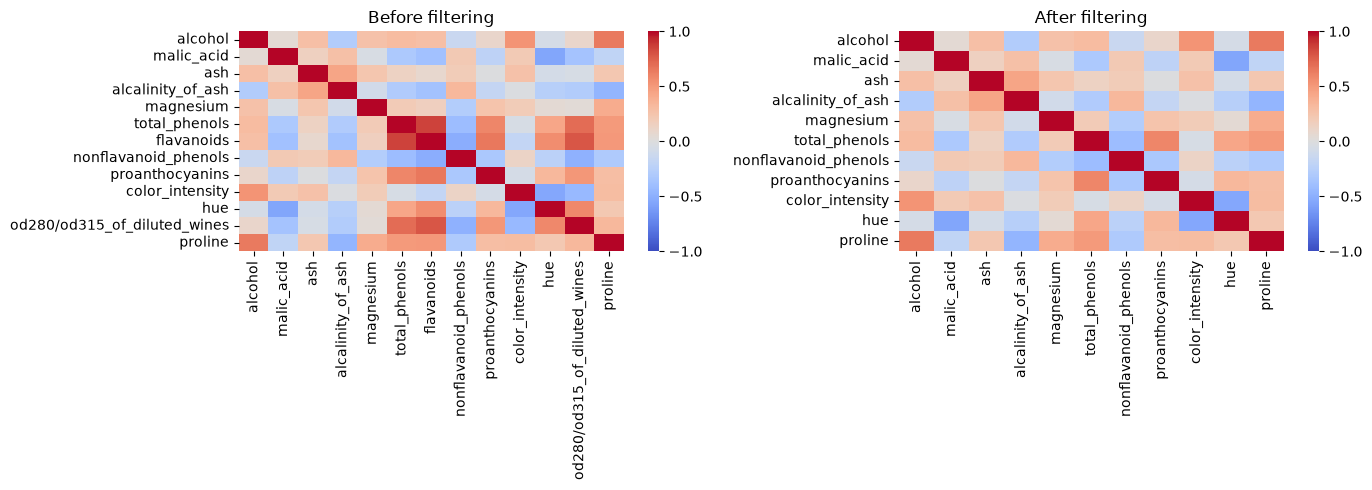

In [13]:
# Select columns using training data; do not inspect the test set to choose drops.
# Make the train/test split first; learn the correlation filter on training data only.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
# Try changing 0.90 to 0.80 or 0.95: the number of removed columns will change.
threshold = 0.7
train_corr = X_train.corr().abs()
upper_train = train_corr.where(np.triu(np.ones(train_corr.shape), k=1).astype(bool))
# This simple filter keeps the earlier column when a pair exceeds the threshold.
# It ignores class labels, so it may remove a feature that helps prediction.
to_drop = [col for col in upper_train.columns if (upper_train[col] > threshold).any()]
# Feature selection is learned from training data, then applied unchanged to test data.
keep = X_train.columns.drop(to_drop)
print('Dropped:', to_drop)
print('Original features:', X_train.shape[1], 'Remaining:', len(keep))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(X_train.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Before filtering')
sns.heatmap(X_train[keep].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('After filtering')
plt.tight_layout(); plt.show()

## 6. PCA creates new features instead

PCA creates new variables rather than choosing a subset of the original ones. Scale the features first, then inspect how much variance each principal component explains.

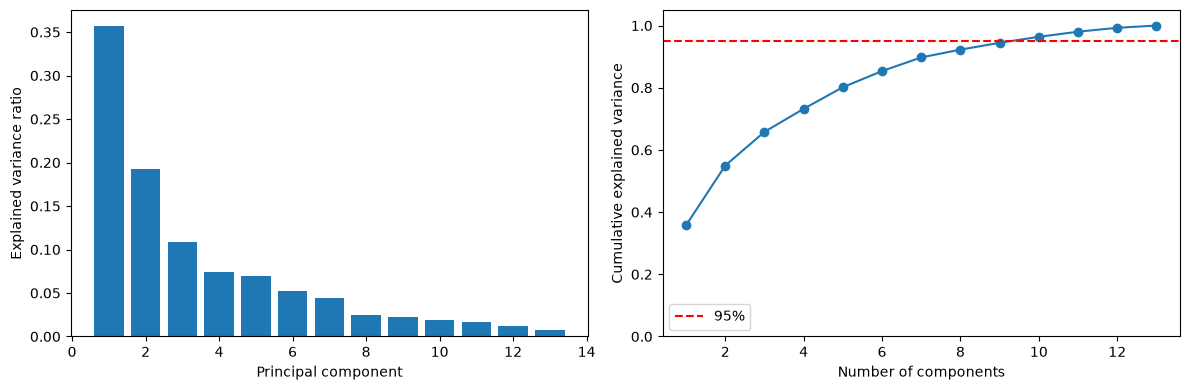

Components needed for 95% variance: 10


In [6]:
# fit_transform learns from training data; transform applies the same rule to test data.
# PCA responds to variance. Standardization stops large-unit features dominating the result.
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train)
test_scaled = scaler.transform(X_test)
# Fit all principal directions first so we can inspect the explained variance.
pca = PCA().fit(train_scaled)
variance = pca.explained_variance_ratio_
# Add component contributions to see the total variance preserved by the first k PCs.
cumulative = np.cumsum(variance)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(variance)+1), variance)
axes[0].set(xlabel='Principal component', ylabel='Explained variance ratio')
axes[1].plot(range(1, len(cumulative)+1), cumulative, 'o-')
# The dashed line shows a variance target, not a desired prediction accuracy.
axes[1].axhline(.95, color='red', ls='--', label='95%')
axes[1].set(xlabel='Number of components', ylabel='Cumulative explained variance', ylim=(0, 1.05))
axes[1].legend(); plt.tight_layout(); plt.show()
print('Components needed for 95% variance:', np.searchsorted(cumulative, .95)+1)

## 7. Visualize the first two components

Plot the first two principal components and colour the samples by class. This is a two-dimensional representation of the original 13-dimensional data.

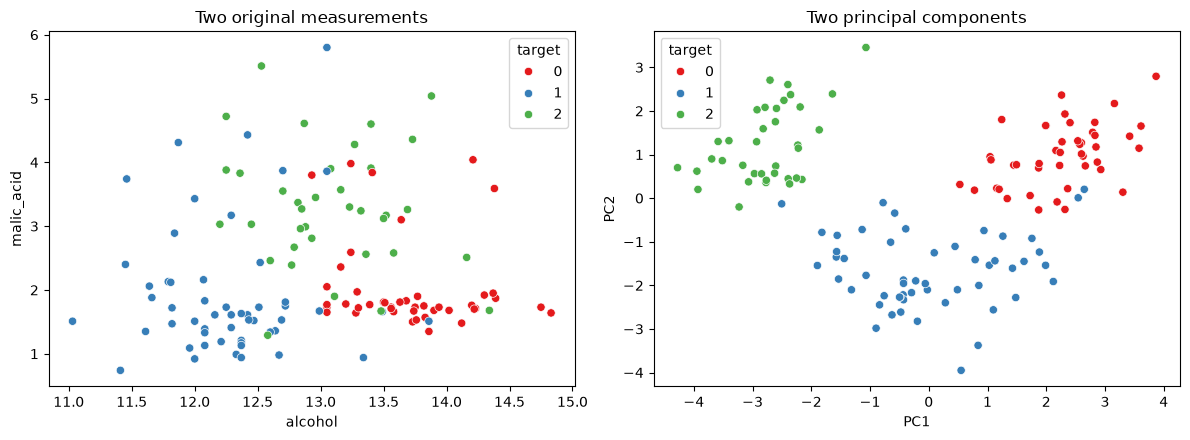

Variance retained by two PCs: 0.55


In [7]:
# The points are projected onto two new principal-component axes.
# Two PCs let us draw the 13-feature dataset on a 2D graph.
pca2 = PCA(n_components=2)
# The new x and y coordinates are combinations of original measurements.
Z_train = pca2.fit_transform(train_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# Compare two original features with two new PCA directions; the axes are not equivalent.
sns.scatterplot(x=X_train.iloc[:, 0], y=X_train.iloc[:, 1], hue=y_train, palette='Set1', ax=axes[0])
axes[0].set_title('Two original measurements')
sns.scatterplot(x=Z_train[:, 0], y=Z_train[:, 1], hue=y_train, palette='Set1', ax=axes[1])
axes[1].set(xlabel='PC1', ylabel='PC2', title='Two principal components')
plt.tight_layout(); plt.show()
print('Variance retained by two PCs:', round(pca2.explained_variance_ratio_.sum(), 3))

## 8. Two ways to choose PCA components

**Fixed number:** `n_components=5` keeps exactly five principal components.  
**Variance threshold:** `n_components=0.95` automatically keeps enough components to explain at least 95% of the **training-set variance**.

Both methods create new features. Compare the number of components, retained variance, and classification performance using the same KNN model. The 95% threshold does not mean 95% accuracy.

Compare the actual number of PCs chosen, the retained variance, and the final accuracy. These are three different measurements.

,Components,Retained variance (%),Test accuracy (%)
Method,,,
Fixed: 5 components,5,80.16,97.78
Variance: at least 95%,10,96.37,95.56


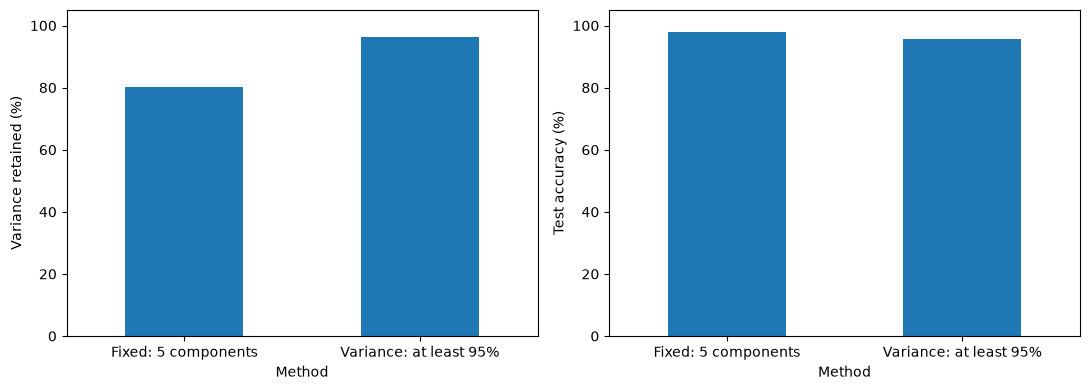

In [8]:
# Compare a fixed component count with an explained-variance target.
# The Pipeline fits standardization and PCA using training data only.
# Method A asks for exactly 5 PCs; method B asks for at least 95% retained variance.
# It is variance, not covariance, that the 95% setting preserves.
pca_options = {
    'Fixed: 5 components': PCA(n_components=5),
    'Variance: at least 95%': PCA(n_components=0.95, svd_solver='full')
}

pca_rows = []
for name, transformer in pca_options.items():
    model = Pipeline([
        ('scale', StandardScaler()),
        ('pca', transformer),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])
    # Each pipeline fits the scaler and PCA on the training split only.
    model.fit(X_train, y_train)
    selected_pca = model.named_steps['pca']
    predictions = model.predict(X_test)
    pca_rows.append({
        'Method': name,
        # Method B chooses its component count automatically.
        'Components': selected_pca.n_components_,
        'Retained variance (%)': 100 * selected_pca.explained_variance_ratio_.sum(),
        'Test accuracy (%)': 100 * accuracy_score(y_test, predictions)
    })

# More retained variance need not lead to higher classification accuracy.
pca_results = pd.DataFrame(pca_rows).set_index('Method')
display(pca_results.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pca_results['Retained variance (%)'].plot.bar(ax=axes[0], rot=0, ylabel='Variance retained (%)')
pca_results['Test accuracy (%)'].plot.bar(ax=axes[1], rot=0, ylabel='Test accuracy (%)')
axes[0].set_ylim(0, 105)
axes[1].set_ylim(0, 105)
plt.tight_layout()
plt.show()

## 9. Original features vs filtering vs PCA

Evaluate three approaches with the same split and classifier: all original features, correlation-filtered features, and PCA components. Reducing dimensions is not guaranteed to increase accuracy.

All three approaches use the same KNN settings. The test set is used only for the final comparison.

,Features/components,Test accuracy
Approach,,
All original features,13,0.933
Correlation filtering,13,0.933
PCA (95% variance),10,0.956


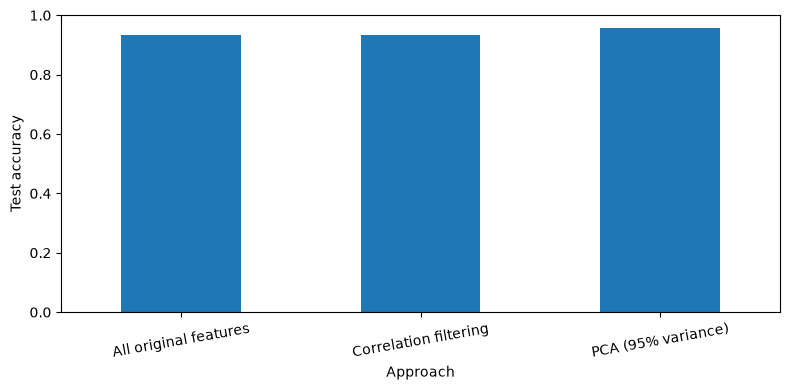

In [9]:
# Use the same model settings and held-out test set for a fair comparison.
# The test set is never used to choose features or fit PCA.
# Hold KNN and the train/test split fixed: only the feature representation changes.
models = {
    'All original features': (X_train, X_test, Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])),
    # Keep existing measurements, but remove columns selected by correlation.
    'Correlation filtering': (X_train[keep], X_test[keep], Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])),
    # Replace original measurements with principal-component scores.
    'PCA (95% variance)': (X_train, X_test, Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=.95, svd_solver='full')), ('knn', KNeighborsClassifier(n_neighbors=5))]))
}
rows = []
for label, (tr, te, model) in models.items():
    model.fit(tr, y_train)
    pred = model.predict(te)
    count = model.named_steps['pca'].n_components_ if 'pca' in model.named_steps else tr.shape[1]
    rows.append({'Approach': label, 'Features/components': count, 'Test accuracy': accuracy_score(y_test, pred)})
# Judge trade-offs using both dimensionality and accuracy, not accuracy alone.
comparison = pd.DataFrame(rows).set_index('Approach')
display(comparison.round(3))
comparison['Test accuracy'].plot.bar(figsize=(8, 4), ylim=(0, 1), rot=10, ylabel='Test accuracy')
plt.tight_layout(); plt.show()

## 10. What happens when we change the number of components?

Use cross-validation on the training set to see how model performance changes with the number of components. The highest explained variance is not necessarily the best predictive setting.

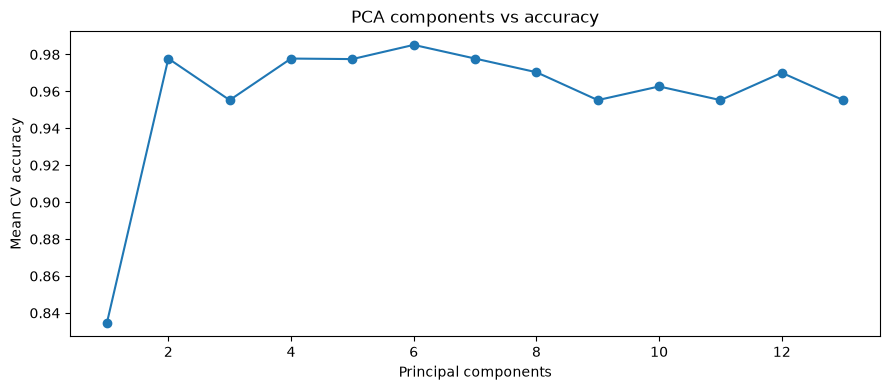

Best k by CV: 6


In [10]:
# Fit scaling and PCA inside cross-validation for each component count.
# Select component counts by cross-validation on the training set.
# Test 1, 2, ..., 13 principal components on training folds only.
counts = range(1, X_train.shape[1] + 1)
scores = []
for k in counts:
    pipe = Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=k)),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])
    # Scaling and PCA are refitted within each fold by the pipeline.
    scores.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy').mean())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(counts), scores, 'o-')
ax.set(xlabel='Principal components', ylabel='Mean CV accuracy', title='PCA components vs accuracy')
plt.tight_layout(); plt.show()
# The highest CV accuracy may occur before retaining all variance.
print('Best k by CV:', list(counts)[int(np.argmax(scores))])

## 11. Discussion
- Are high correlation and equal variance the same?
- Did the second correlated feature improve prediction?
- Why can PCA lose predictive information?
- Which representation would you use for this dataset?
- How did choosing a fixed number of components differ from setting a 95% variance target?
- Did the method that retained more variance also give higher test accuracy?